Penjelasan Kode Praktikum Text Classification
1. Import Library dan Memuat Dataset
Kode ini mengimpor library Pandas dan membaca dataset dari file CSV. Fungsi head() menampilkan lima baris pertama untuk melihat struktur dan isi dataset.

In [2]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


2. Download Resource NLTK dan Import Library Preprocessing
Kode ini mengunduh resource yang dibutuhkan oleh NLTK, seperti tokenizer, stopwords, dan WordNet. Beberapa library juga diimpor untuk mendukung proses pembersihan dan pengolahan teks.

In [4]:
# DownLoad resource NLTK yang diperLukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Import Library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk. tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi Lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text. lower() # Ubah menjadi Lowercase
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text. translate(str.maketrans('', '', string. punctuation))
    words = word_tokenize(text) # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english' )] # Hapus stopwords
    words = [lemmatizer. lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text' ] = df['Message' ].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing: \n", df[['Message', 'clean_text' ]].head())

# Hapus tanda baca

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\personal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\personal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\personal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\personal\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



Hasil Preprocessing: 
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


3. Fungsi Preprocessing Teks
Kode ini membersihkan teks melalui beberapa proses, yaitu mengubah huruf menjadi kecil, menghapus angka dan tanda baca, melakukan tokenisasi, menghapus stopwords, serta melakukan lemmatisasi.

In [5]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


4. Menerapkan Preprocessing pada Dataset
Kode ini menerapkan fungsi clean_text() pada seluruh pesan dalam kolom Message. Hasilnya disimpan dalam kolom baru bernama clean_text, kemudian ditampilkan untuk memeriksa hasil pembersihan teks.

In [7]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan label
X = df['clean_text' ]
y = df['Category' ]

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

5. Mengubah Label Kategori
Kode ini mengubah label kategori ham menjadi angka 0 dan spam menjadi angka 1. Fungsi value_counts() digunakan untuk menghitung jumlah data pada setiap kategori.

In [8]:
from sklearn. feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer. fit_transform(X_train)
X_test_tfidf = vectorizer. transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf. shape)


TF-IDF Shape (Train): (4457, 5000)


6. Membagi Dataset Menjadi Data Training dan Testing
Kode ini membagi dataset menjadi 80% data training dan 20% data testing. Data training digunakan untuk melatih model, sedangkan data testing digunakan untuk mengevaluasi performa model.

In [9]:
from sklearn. naive_bayes import MultinomialNB

# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

7. Ekstraksi Fitur Menggunakan TF-IDF
Kode ini mengubah teks menjadi representasi numerik menggunakan metode TF-IDF. Parameter ngram_range=(1,2) memungkinkan penggunaan fitur berupa satu kata dan kombinasi dua kata, sedangkan max_features=5000 membatasi jumlah fitur maksimum menjadi 5.000.

In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



8. Inisialisasi dan Pelatihan Model Naïve Bayes
Kode ini membuat model klasifikasi menggunakan algoritma Multinomial Naïve Bayes dengan parameter alpha=0.1. Model kemudian dilatih menggunakan data training dan digunakan untuk memprediksi kategori pada data testing.

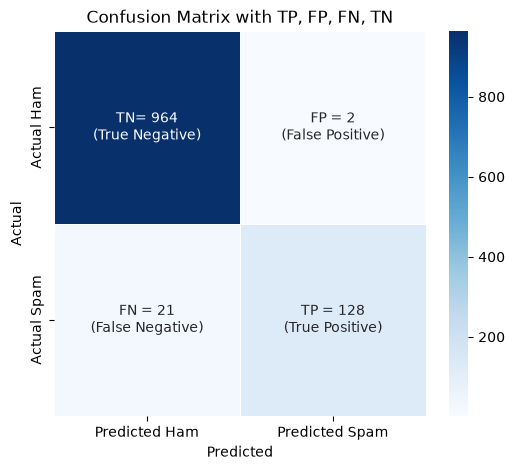

In [11]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])

# Label untuk TP, FP, FN, TN
labels = np.array([["TN= {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])

# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)

# Tambahkan Label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')
plt.show()

9. Evaluasi Model Klasifikasi
Kode ini menghitung akurasi model menggunakan accuracy_score() dan menampilkan laporan evaluasi menggunakan classification_report(). Hasil evaluasi mencakup nilai precision, recall, F1-score, dan jumlah data pada setiap kelas.
10. Menghitung Confusion Matrix
Kode ini menghitung confusion matrix berdasarkan label sebenarnya dan hasil prediksi model. Fungsi ravel() digunakan untuk mengambil nilai TN, FP, FN, dan TP sehingga hasil klasifikasi dapat dianalisis.
11. Membuat Visualisasi Confusion Matrix
Kode ini menampilkan confusion matrix dalam bentuk heatmap menggunakan Seaborn dan Matplotlib. Visualisasi dilengkapi dengan nilai TN, FP, FN, dan TP untuk mempermudah pemahaman hasil klasifikasi.

In [13]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
"Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


12. Menguji Klasifikasi pada Teks Baru
Kode ini menguji model menggunakan dua pesan baru. Pesan diproses menggunakan fungsi clean_text(), diubah menjadi fitur TF-IDF, lalu diklasifikasikan sebagai spam atau ham oleh model yang telah dilatih.